# Unemployment Analysis with Python

## 1. Introduction

This project analyzes unemployment data in India.
It explores regional and monthly trends and
examines the impact of COVID-19 on unemployment.

## 2. Objectives

- Analyze unemployment rates across regions.
- Study monthly unemployment trends.
- Compare unemployment rates across states.
- Examine the impact of COVID-19.

## 3. Tools and Libraries

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

In [16]:
# Import required libraries

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [17]:
# Check the current working folder

project_folder = Path.cwd()

print("Project folder:", project_folder)
print("CSV file exists:",
      (project_folder / "Unemployment in India.csv").exists())

Project folder: c:\Users\Shaikh Samiya\Downloads\Unemployement_Analysis
CSV file exists: True


In [18]:
# Load the unemployment dataset

csv_path = project_folder / "Unemployment in India.csv"
df = pd.read_csv(csv_path)

# Display the first five rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [19]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object


In [20]:
# Clean column names by removing extra spaces

df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Duplicate rows: 27


C:\Users\Shaikh Samiya\AppData\Local\Temp\ipykernel_1212\4008253031.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [21]:
# Remove rows with missing values

df = df.dropna().copy()

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Check the cleaned dataset
print("Rows after cleaning:", len(df))
print("Columns after cleaning:", len(df.columns))

# Display the first five cleaned rows
df.head()

Rows after cleaning: 740
Columns after cleaning: 7


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


## 4. Data Cleaning

The original dataset contained 768 rows and 7 columns.
After removing missing and duplicate records, 740 rows
remained. Column names and text values were cleaned,
and the Date column was converted to datetime format.

In [22]:
# Summary statistics of numerical columns

df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [23]:
# Check the date range of the dataset

print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

# Average unemployment rate by region

region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("\nAverage unemployment rate by region:")
print(region_avg)

Start date: 2019-05-31 00:00:00
End date: 2020-06-30 00:00:00

Average unemployment rate by region:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

## 5. Regional Unemployment Analysis

This section compares the average unemployment rate
across different regions in India.

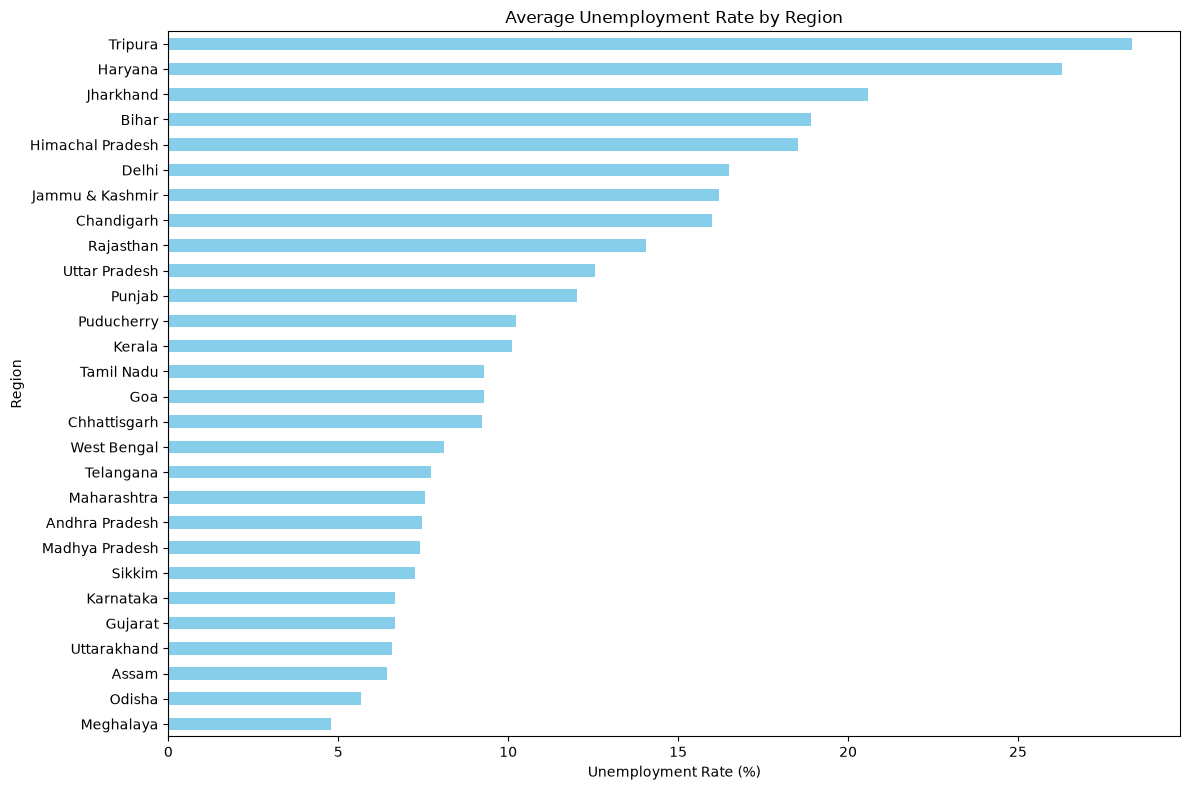

In [24]:
# Plot average unemployment rate by region

plt.figure(figsize=(12, 8))

region_avg.sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

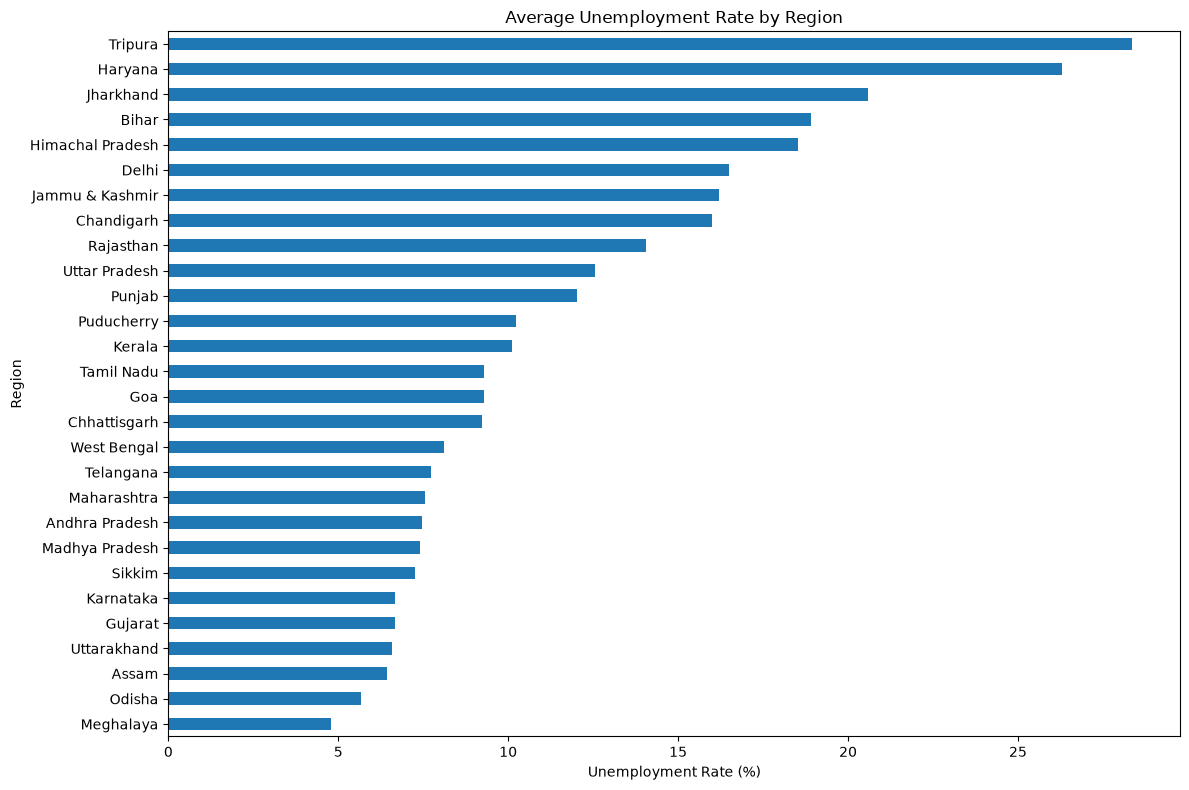

In [25]:
# Save the regional average chart

charts_folder = project_folder / "charts"
charts_folder.mkdir(exist_ok=True)

plt.figure(figsize=(12, 8))

region_avg.sort_values().plot(kind="barh")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()

plt.savefig(
    charts_folder / "01_region_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Monthly Unemployment Trend

This section shows how the unemployment rate
changes over time in India.

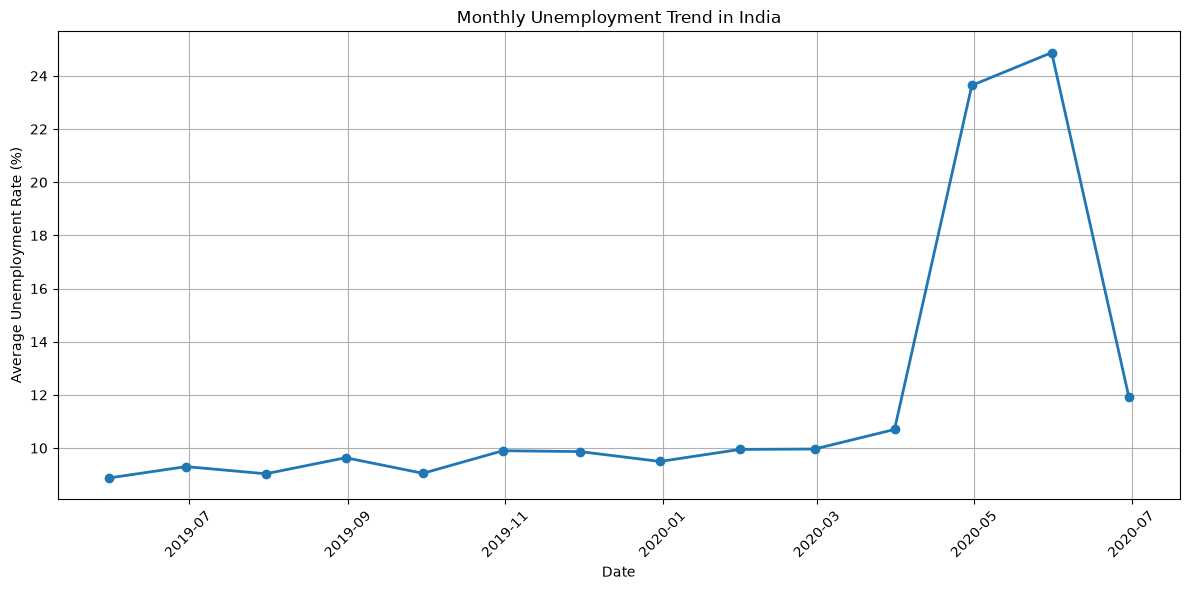

In [26]:
# Calculate average unemployment rate for each month

monthly_avg = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

# Plot monthly unemployment trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Trend in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Save the chart
plt.savefig(
    charts_folder / "02_monthly_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. State-wise Unemployment Trends

This section compares unemployment rates over time
for three selected regions: Maharashtra, Haryana,
and Tamil Nadu.

The line chart helps us understand how unemployment
rates changed in these regions during the study period.

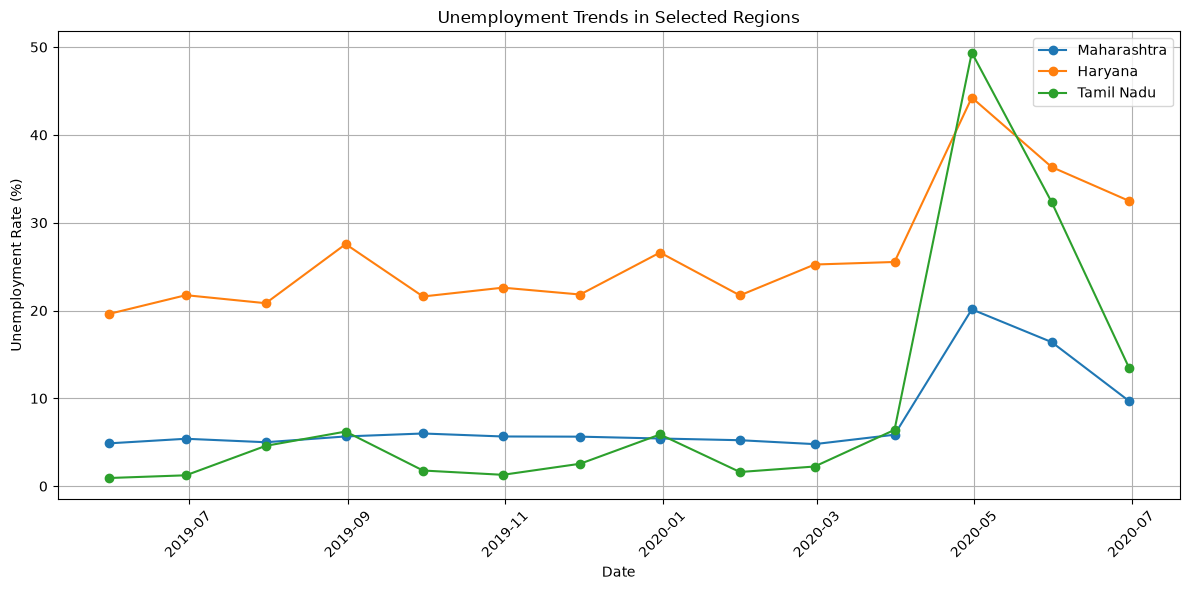

In [27]:
# Select three regions for time-series analysis

selected_regions = ["Maharashtra", "Haryana", "Tamil Nadu"]

plt.figure(figsize=(12, 6))

for region in selected_regions:
    region_data = df[df["Region"] == region]
    region_monthly = (
        region_data.groupby("Date")["Estimated Unemployment Rate (%)"]
        .mean()
        .sort_index()
    )

    plt.plot(
        region_monthly.index,
        region_monthly.values,
        marker="o",
        label=region
    )

plt.title("Unemployment Trends in Selected Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save chart
plt.savefig(
    charts_folder / "03_state_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Top 10 Regions with Highest Unemployment Rate

This chart shows the ten regions with the highest
average unemployment rates during the study period.

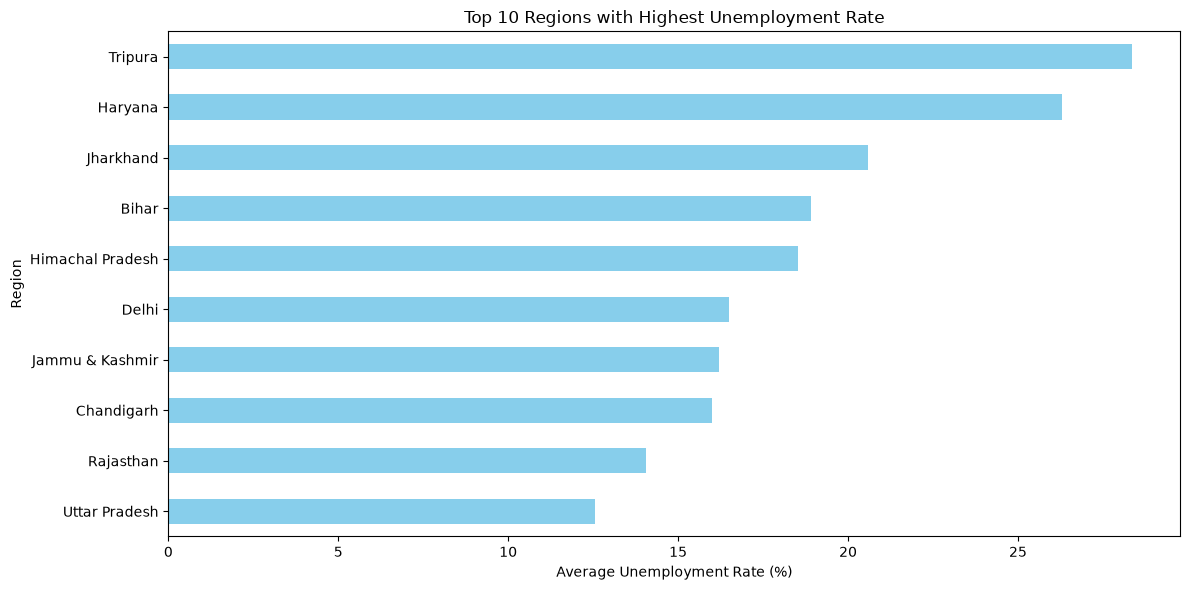

In [28]:
# Find the top 10 regions by average unemployment rate

top_10 = region_avg.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

top_10.sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Top 10 Regions with Highest Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()

# Save chart
plt.savefig(
    charts_folder / "04_top_10_regions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Correlation Heatmap

This heatmap shows the correlation between
unemployment rate, estimated employment, and
labour participation rate.

It helps us understand how these numerical
variables are related to each other.

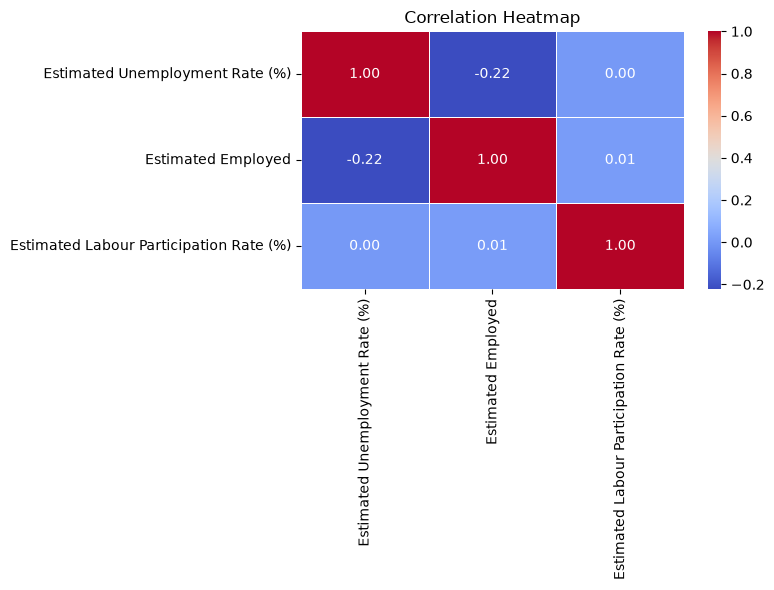

In [29]:
# Select numerical columns for correlation analysis

numeric_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# Calculate correlation matrix
correlation = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()

# Save chart
plt.savefig(
    charts_folder / "05_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. COVID-19 Impact on Unemployment

This section compares the average unemployment
rate before and during the COVID-19 period.

The chart helps visualize how unemployment
changed around the beginning of the pandemic.

Average unemployment before COVID-19: 9.51 %
Average unemployment from March 2020: 17.77 %


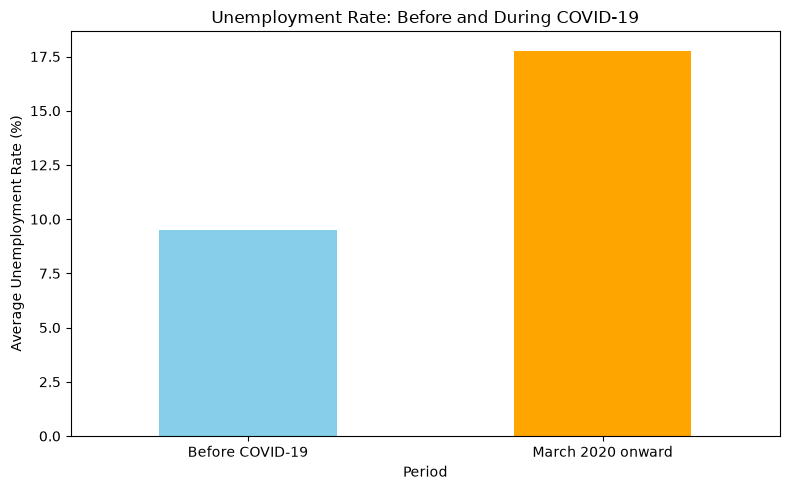

In [30]:
# Define the periods for comparison

pre_covid = df[df["Date"] < "2020-03-01"]
during_covid = df[df["Date"] >= "2020-03-01"]

# Calculate average unemployment rates

pre_covid_avg = pre_covid["Estimated Unemployment Rate (%)"].mean()
during_covid_avg = during_covid["Estimated Unemployment Rate (%)"].mean()

print("Average unemployment before COVID-19:",
      round(pre_covid_avg, 2), "%")

print("Average unemployment from March 2020:",
      round(during_covid_avg, 2), "%")

# Create comparison chart

covid_comparison = pd.Series({
    "Before COVID-19": pre_covid_avg,
    "March 2020 onward": during_covid_avg
})

plt.figure(figsize=(8, 5))

covid_comparison.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Unemployment Rate: Before and During COVID-19")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

# Save chart

plt.savefig(
    charts_folder / "06_covid_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Key Observations

1. The dataset covers the period from May 2019
   to June 2020, allowing us to examine changes
   in unemployment over time.

2. Regional unemployment rates varied across
   the states and regions included in the dataset.

3. The monthly trend chart shows how the average
   unemployment rate changed during the study period.

4. The selected-region chart helps compare
   unemployment trends in Maharashtra, Haryana,
   and Tamil Nadu.

5. The correlation heatmap shows the strength
   and direction of linear relationships between
   the numerical variables.

6. The COVID-19 comparison shows the difference
   between average unemployment rates before
   March 2020 and from March 2020 onward.

## 12. Conclusion

This project analyzed unemployment data in India
using Python. The analysis included data cleaning,
regional comparisons, monthly trends, correlation
analysis, and a comparison of unemployment rates
before and during the COVID-19 period.

The visualizations help identify differences
between regions and changes over time. This
analysis provides a descriptive overview of
unemployment patterns in the dataset.